# Sanity check 2: variant cache == full ESM-C when the "mutation" is the wild type

`forward_variants` recomputes only the K variant positions. Each variant query attends to cached reference keys at non-variant positions, plus the variant keys. Its single approximation is that reference positions never see the variants.

**Why identity should be exact.** If every variant token equals the reference token, then by induction over layers each variant state equals the reference state at that position. The approximation then has nothing to approximate. So `forward_variants(ref, positions, ids[positions])` must reproduce the full forward `model(ids)` at those positions, in every layer, up to fp32 rounding.

The notebook checks:
1. **Identity across K and proteins.** Final hidden, logits and every layer's residual are compared with the full forward and with the bruteforce oracle. K ranges from 1 to every token, including `<cls>`/`<eos>`.
2. **Negative control.** Identity alone would also pass if the cache just returned the reference. So the batch mixes identity rows with real mutants: identity rows must equal WT, mutant rows must *differ* from WT, and every row must match the bruteforce oracle. For single mutants, the size of the approximation gap against an exact full forward is shown for scale.
3. **Padding (`var_mask`).** Padded slots and all-padded rows reproduce WT.
4. **Official model.** Cache logits are compared against the official `esm` ESM-C full forward.
5. **bf16.** The cache's deviation from fp32 is compared with the full bf16 forward's own deviation from fp32.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import torch

from mutant_cache.backbone import CANONICAL_AA, load_esmc
from mutant_cache.data.paths import raw_dir

DEV = "cuda" if torch.cuda.is_available() else "cpu"
N_COPIES = 4          # identity rows per call (batching must not matter)
g = torch.Generator().manual_seed(0)

model = load_esmc("esmc_300m", device=DEV, dtype=torch.float32).freeze_base()
tok = model.tokenizer
AA_IDS = torch.tensor([tok.aa_to_id[a] for a in CANONICAL_AA])

Proteins: ubiquitin plus three ProteinGym targets of different lengths.

In [2]:
pg = pd.read_csv(raw_dir("proteingym") / "DMS_substitutions.csv").drop_duplicates("UniProt_ID")
pg = pg[pg.target_seq.map(lambda s: set(s) <= set(CANONICAL_AA))]
SEQS = {"UBQ": "MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG"}
for lo, hi in [(100, 160), (230, 300), (420, 520)]:
    r = pg[pg.seq_len.between(lo, hi)].sample(1, random_state=0).iloc[0]
    SEQS[r.UniProt_ID] = r.target_seq
{k: len(v) for k, v in SEQS.items()}

{'UBQ': 76, 'KCNE1_HUMAN': 129, 'BLAT_ECOLX': 286, 'NCAP_I34A1': 498}

## Helpers

`full` is the exact oracle `model(ids)`. A cache output's per-layer residual (`layer_hidden[i]`, the output of block *i*) is compared with `full.layer_inputs[i+1]`, and the last one with `full.hidden_prenorm`. Residual diffs are reported relative to the residual stream's max magnitude, which grows through the layers.

In [3]:
def full_at(full, positions):
    """Full-forward quantities at `positions`, shaped like a VariantOutput (batch 1)."""
    layers = [x[:, positions] for x in full.layer_inputs[1:]] + [full.hidden_prenorm[:, positions]]
    return dict(hidden=full.hidden[:, positions], logits=full.logits[:, positions], layers=layers)


def diff(vout, tgt):
    """Max |diff| of a VariantOutput (N rows) vs a target dict (broadcast over N)."""
    md = lambda a, b: (a.float() - b.float()).abs().max().item()
    rel = max(md(a, b) / b.abs().max().clamp_min(1).item()
              for a, b in zip(vout.layer_hidden, tgt["layers"]))
    return dict(hidden=md(vout.hidden, tgt["hidden"]), logits=md(vout.logits, tgt["logits"]),
                layers_rel=rel)


def as_target(vout):
    return dict(hidden=vout.hidden, logits=vout.logits, layers=vout.layer_hidden)


def random_positions(L_tok, K, residues_only=True):
    if not residues_only:
        return torch.randperm(L_tok, generator=g)[:K].sort().values
    return (torch.randperm(L_tok - 2, generator=g)[:K] + 1).sort().values


TOL = dict(hidden=1e-4, logits=1e-3, layers_rel=1e-5)   # same as tests/test_cache_equivalence.py
def ok(d, tol=TOL):
    return all(d[k] < tol[k] for k in tol)


refs, fulls = {}, {}
with torch.no_grad():
    for name, s in SEQS.items():
        ids = tok.encode(s).to(DEV)
        fulls[name] = model(ids[None])
        refs[name] = model.forward_reference(ids)
        # trivial but cheap: the cached reference *is* the full forward
        assert torch.equal(refs[name].final, fulls[name].hidden)

## 1. Identity across K and proteins

For each protein and each K: random positions, variant ids equal to the reference ids, `N_COPIES` identical rows. Columns ending `_full` compare against `model(ids)`; columns ending `_brute` compare against `forward_variants_bruteforce`. `K=all_tok` also substitutes `<cls>` and `<eos>`, which leaves the cross-attention branch with no keys at all.

In [4]:
rows = []
with torch.no_grad():
    for name, s in SEQS.items():
        ref, full = refs[name], fulls[name]
        Lt = ref.seq_len
        for K in [1, 2, 5, 10, 25, 50, "all_res", "all_tok"]:
            if K == "all_res":
                pos = torch.arange(1, Lt - 1)
            elif K == "all_tok":
                pos = torch.arange(Lt)
            else:
                pos = random_positions(Lt, K)
            pos = pos.to(DEV)
            vid = ref.ids[pos][None].repeat(N_COPIES, 1)
            v = model.forward_variants(ref, pos, vid, output_layers=True)
            b = model.forward_variants_bruteforce(ref, pos, vid, output_layers=True)
            d_full, d_brute = diff(v, full_at(full, pos)), diff(v, as_target(b))
            rows.append(dict(protein=name, L=len(s), K=K if isinstance(K, int) else f"{K} ({len(pos)})",
                             **{f"{k}_full": x for k, x in d_full.items()},
                             **{f"{k}_brute": x for k, x in d_brute.items()},
                             pass_=ok(d_full) and ok(d_brute)))
ident = pd.DataFrame(rows)
pd.set_option("display.float_format", "{:.1e}".format)
ident

,protein,L,K,hidden_full,logits_full,layers_rel_full,hidden_brute,logits_brute,layers_rel_brute,pass_
0,UBQ,76,1,1.9e-07,1.7e-05,1.6e-06,1.9e-07,1.9e-05,1.2e-06,True
1,UBQ,76,2,3.1e-07,2.7e-05,2.0e-06,4.5e-07,2.9e-05,1.7e-06,True
2,UBQ,76,5,4.8e-07,4.1e-05,2.1e-06,6.0e-07,6.5e-05,3.6e-06,True
3,UBQ,76,10,6.0e-07,5.1e-05,2.2e-06,6.9e-07,4.6e-05,2.4e-06,True
4,UBQ,76,25,6.3e-07,6.5e-05,2.4e-06,5.4e-07,5.3e-05,2.0e-06,True
5,UBQ,76,50,1.1e-06,7.8e-05,3.6e-06,1.1e-06,9.7e-05,3.9e-06,True
6,UBQ,76,all_res (76),8.3e-07,8.8e-05,2.9e-06,9.2e-07,1.0e-04,2.6e-06,True
7,UBQ,76,all_tok (78),1.0e-06,8.8e-05,8.3e-07,8.9e-07,6.5e-05,1.0e-06,True
8,KCNE1_HUMAN,129,1,5.4e-07,3.3e-05,7.7e-07,7.7e-07,4.0e-05,1.1e-06,True
9,KCNE1_HUMAN,129,2,4.5e-07,3.3e-05,9.8e-07,6.0e-07,3.1e-05,1.2e-06,True


In [5]:
print("worst over all proteins/K:")
print(ident.filter(like="_").drop(columns="pass_").max().to_string())
print("all pass:", ident.pass_.all())

worst over all proteins/K:
hidden_full        3.1e-06
logits_full        2.0e-04
layers_rel_full    8.3e-06
hidden_brute       3.4e-06
logits_brute       2.2e-04
layers_rel_brute   5.1e-06
all pass: True


## 2. Negative control: real mutants in the same batch

Same K positions, N=8 rows. Row 0 is the identity. Rows 1–7 substitute a random *different* residue at every slot.
- Row 0 must still equal WT. Batching must not leak between rows.
- Rows 1–7 must differ from WT by a lot.
- All rows must match the bruteforce oracle.

The per-layer plot shows where the mutants diverge from WT.

In [6]:
def mutate(ref_ids, n, gen):
    """(n, K) random residues, each different from the reference at that slot."""
    out = AA_IDS[torch.randint(0, 20, (n, ref_ids.numel()), generator=gen)].to(ref_ids.device)
    clash = out == ref_ids
    while clash.any():
        out[clash] = AA_IDS[torch.randint(0, 20, (int(clash.sum()),), generator=gen)].to(ref_ids.device)
        clash = out == ref_ids
    return out


neg = []
with torch.no_grad():
    for name in SEQS:
        ref, full = refs[name], fulls[name]
        for K in [1, 3, 10]:
            pos = random_positions(ref.seq_len, K).to(DEV)
            wt = ref.ids[pos][None]
            vid = torch.cat([wt, mutate(wt[0], 7, g)])
            v = model.forward_variants(ref, pos, vid, output_layers=True)
            b = model.forward_variants_bruteforce(ref, pos, vid, output_layers=True)
            tgt = full_at(full, pos)
            row0 = diff(type(v)(hidden=v.hidden[:1], logits=v.logits[:1],
                                layer_hidden=[x[:1] for x in v.layer_hidden]), tgt)
            mut_vs_wt = (v.logits[1:] - tgt["logits"]).abs().amax(dim=(1, 2))   # per mutant row
            neg.append(dict(protein=name, K=K, row0_logits_vs_wt=row0["logits"],
                            min_mutant_logits_vs_wt=mut_vs_wt.min().item(),
                            all_rows_vs_brute=diff(v, as_target(b))["logits"],
                            pass_=ok(row0) and mut_vs_wt.min().item() > 0.1
                                  and ok(diff(v, as_target(b)))))
neg = pd.DataFrame(neg)
neg

,protein,K,row0_logits_vs_wt,min_mutant_logits_vs_wt,all_rows_vs_brute,pass_
0,UBQ,1,2.2e-05,1.0e+01,1.3e-04,True
1,UBQ,3,3.6e-05,1.1e+01,8.4e-05,True
2,UBQ,10,3.8e-05,1.8e+01,5.0e-05,True
3,KCNE1_HUMAN,1,1.7e-05,4.8e+00,2.8e-05,True
4,KCNE1_HUMAN,3,3.1e-05,5.0e+00,5.3e-05,True
5,KCNE1_HUMAN,10,5.3e-05,8.4e+00,7.2e-05,True
6,BLAT_ECOLX,1,1.8e-05,5.6e+00,4.5e-05,True
7,BLAT_ECOLX,3,3.8e-05,6.5e+00,7.8e-05,True
8,BLAT_ECOLX,10,5.8e-05,1.4e+01,8.9e-05,True
9,NCAP_I34A1,1,1.5e-05,2.1e+00,1.8e-05,True


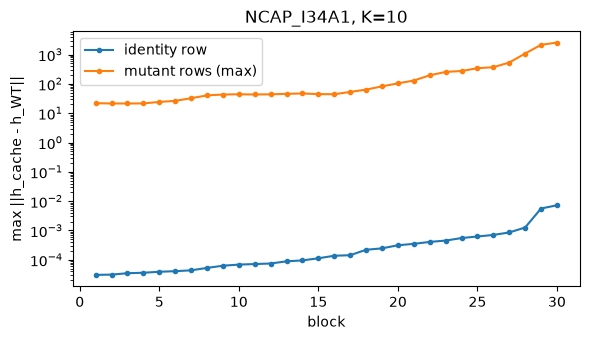

In [7]:
# where do identity vs mutant rows depart from WT, layer by layer? (last protein, K=10)
L_ = model.n_layers
d_id = [(a[0] - b[0]).norm(dim=-1).max().item() for a, b in zip(v.layer_hidden, tgt["layers"])]
d_mut = [(a[1:] - b[0]).norm(dim=-1).max().item() for a, b in zip(v.layer_hidden, tgt["layers"])]
plt.figure(figsize=(6, 3.5))
plt.semilogy(range(1, L_ + 1), [max(x, 1e-12) for x in d_id], "o-", ms=3, label="identity row")
plt.semilogy(range(1, L_ + 1), d_mut, "o-", ms=3, label="mutant rows (max)")
plt.xlabel("block"); plt.ylabel("max ||h_cache - h_WT||"); plt.title(f"{name}, K={K}")
plt.legend(); plt.tight_layout(); plt.show()

### For scale: the approximation gap on real single mutants

This compares the cache against an **exact** full forward of the mutant sequence. Here the reference positions *should* have seen the mutation, so a non-zero gap is expected: it is the cache approximation, not a bug. It is shown only so the identity residuals above can be read against a real error size.

In [8]:
gap = []
with torch.no_grad():
    for name in SEQS:
        ref = refs[name]
        for p in random_positions(ref.seq_len, 8).tolist():
            pos = torch.tensor([p], device=DEV)
            alt = mutate(ref.ids[pos], 1, g)
            v = model.forward_variants(ref, pos, alt)
            mut_ids = ref.ids.clone(); mut_ids[p] = alt[0, 0]
            ex = model(mut_ids[None])
            lp_c = torch.log_softmax(v.logits[0, 0], -1)
            lp_e = torch.log_softmax(ex.logits[0, p], -1)
            gap.append(dict(protein=name, logits_vs_exact=(v.logits[0, 0] - ex.logits[0, p]).abs().max().item(),
                            hidden_cos=torch.cosine_similarity(v.hidden[0, 0], ex.hidden[0, p], 0).item(),
                            logprob_vs_exact=(lp_c - lp_e).abs().max().item()))
gap = pd.DataFrame(gap)
print(f"identity worst logits diff : {ident.logits_full.max():.1e}")
print(f"single-mutant approx. gap  : logits median {gap.logits_vs_exact.median():.2e}, "
      f"max {gap.logits_vs_exact.max():.2e}; hidden cos min {gap.hidden_cos.min():.5f}")

identity worst logits diff : 2.0e-04
single-mutant approx. gap  : logits median 1.07e+00, max 8.00e+00; hidden cos min 0.94101


## 3. Padding with `var_mask`

A real mutation in slot 0 plus padded slots carrying the reference token, with `var_mask=False` on the pads. The padded slots must equal WT. A row padded at every slot must equal WT everywhere. Unmasked identity slots and masked pad slots must give the same answer.

In [9]:
pad_rows = []
with torch.no_grad():
    for name in SEQS:
        ref, full = refs[name], fulls[name]
        pos = random_positions(ref.seq_len, 6).to(DEV)
        wt = ref.ids[pos]
        vid = wt[None].repeat(3, 1)
        vid[0, 0] = mutate(wt[:1], 1, g)[0, 0]          # row 0: one real mutation + 5 pads
        vm = torch.ones(3, 6, dtype=torch.bool, device=DEV)
        vm[0, 1:] = False
        vm[1] = False                                    # row 1: all pads
        # row 2: unmasked identity
        v = model.forward_variants(ref, pos, vid, var_mask=vm, output_layers=True)
        b = model.forward_variants_bruteforce(ref, pos, vid, var_mask=vm, output_layers=True)
        tgt = full_at(full, pos)
        pad_rows.append(dict(
            protein=name,
            row0_pads_vs_wt=(v.logits[0, 1:] - tgt["logits"][0, 1:]).abs().max().item(),
            row1_allpad_vs_wt=(v.logits[1] - tgt["logits"][0]).abs().max().item(),
            row2_identity_vs_wt=(v.logits[2] - tgt["logits"][0]).abs().max().item(),
            vs_brute=diff(v, as_target(b))["logits"]))
pad = pd.DataFrame(pad_rows)
pad

,protein,row0_pads_vs_wt,row1_allpad_vs_wt,row2_identity_vs_wt,vs_brute
0,UBQ,2.1e-05,3.1e-05,9.5e-05,1.1e-04
1,KCNE1_HUMAN,2.3e-05,2.3e-05,4.2e-05,6.5e-05
2,BLAT_ECOLX,2.1e-05,2.3e-05,3.1e-05,7.2e-05
3,NCAP_I34A1,2.9e-05,2.9e-05,2.7e-05,2.9e-05


## 4. Against the official `esm` ESM-C

This closes the loop: cache identity logits are compared with the official package's full forward, in fp32. The official model is loaded on CPU and moved to the GPU, because on CUDA `from_pretrained` casts to bf16.

In [10]:
# The official esm warns at import that fused kernels (Transformer Engine,
# xformers, flash-attn) are missing. That is deliberate: the pure-PyTorch path
# is the one our port matches bit-for-bit; fused kernels would make it drift.
import logging
logging.getLogger("esm.models.esmc.kernels").setLevel(logging.ERROR)
from esm.models.esmc import ESMC as OfficialESMC
official = OfficialESMC.from_pretrained("esmc_300m", device="cpu", use_flash_attn=False).to(DEV).eval()
off_rows = []
with torch.no_grad():
    for name, s in SEQS.items():
        ref = refs[name]
        off_logits = official(sequence_tokens=official._tokenize([s]).to(DEV)).sequence_logits
        pos = random_positions(ref.seq_len, 10).to(DEV)
        v = model.forward_variants(ref, pos, ref.ids[pos][None])
        off_rows.append(dict(protein=name,
                             cache_vs_official_logits=(v.logits[0] - off_logits[0, pos]).abs().max().item(),
                             argmax_agree=(v.logits[0].argmax(-1) == off_logits[0, pos].argmax(-1)).float().mean().item()))
del official; torch.cuda.empty_cache()
off = pd.DataFrame(off_rows)
off

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

,protein,cache_vs_official_logits,argmax_agree
0,UBQ,4.8e-05,1.0e+00
1,KCNE1_HUMAN,3.4e-05,1.0e+00
2,BLAT_ECOLX,4.2e-05,1.0e+00
3,NCAP_I34A1,2.6e-05,1.0e+00


## 5. bf16

In bf16, the full forward uses bf16 SDPA, while the cache computes attention scores and softmax in fp32 (INTERFACES.md). So cache and full forward will not agree bit-for-bit. The meaningful check is that the cache is no further from the fp32 truth than the full bf16 forward is.

In [11]:
m16 = load_esmc("esmc_300m", device=DEV, dtype=torch.bfloat16).freeze_base()
bf = []
with torch.no_grad():
    for name, s in SEQS.items():
        ids = tok.encode(s).to(DEV)
        full16 = m16(ids[None]); ref16 = m16.forward_reference(ids)
        pos = random_positions(ref16.seq_len, 10).to(DEV)
        v16 = m16.forward_variants(ref16, pos, ids[pos][None])
        truth = fulls[name].logits[0, pos]
        bf.append(dict(protein=name,
                       cache16_vs_full16=(v16.logits[0].float() - full16.logits[0, pos].float()).abs().max().item(),
                       cache16_vs_fp32=(v16.logits[0].float() - truth).abs().max().item(),
                       full16_vs_fp32=(full16.logits[0, pos].float() - truth).abs().max().item()))
del m16; torch.cuda.empty_cache()
bf = pd.DataFrame(bf)
bf

,protein,cache16_vs_full16,cache16_vs_fp32,full16_vs_fp32
0,UBQ,5.0e-01,5.9e-01,5.9e-01
1,KCNE1_HUMAN,4.4e-01,6.4e-01,7.0e-01
2,BLAT_ECOLX,7.5e-01,7.6e-01,7.1e-01
3,NCAP_I34A1,2.5e-01,2.2e-01,3.1e-01


## Verdict

In [12]:
checks = {
    "identity == full forward, all proteins & K (fp32)": ident.pass_.all(),
    "identity row in a mutant batch == WT; mutants differ; all == bruteforce": neg.pass_.all(),
    "identity residual << single-mutant approximation gap": ident.logits_full.max() < 1e-2 * gap.logits_vs_exact.median(),
    "var_mask pads / all-pad rows == WT": (pad.drop(columns="protein") < TOL["logits"]).all().all(),
    "cache identity == official esm full forward (fp32)": (off.cache_vs_official_logits < TOL["logits"]).all()
                                                          and (off.argmax_agree == 1).all(),
    "bf16 cache no further from fp32 than full bf16 (2x + 0.1)": (bf.cache16_vs_fp32 < 2 * bf.full16_vs_fp32 + 0.1).all(),
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
assert all(checks.values())

PASS identity == full forward, all proteins & K (fp32)
PASS identity row in a mutant batch == WT; mutants differ; all == bruteforce
PASS identity residual << single-mutant approximation gap
PASS var_mask pads / all-pad rows == WT
PASS cache identity == official esm full forward (fp32)
PASS bf16 cache no further from fp32 than full bf16 (2x + 0.1)
